# Conformal Data Cleaning (CDC)


The concept behind this is for every column to learn a range of believable values from other columns. A value outisde the learned range is an error and is replaced by the model's best guess.
Predictions made through CDC makes sure that the range is correct with a chosen confidence level.

### 1. Setup

In [9]:
%pip install -q numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [10]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score

datasets = [823, 30, 40498]              # 823- houses, 30- page-block, 40498- wine-quality
confidence_levels = [0.5, 0.8, 0.999]    # as mentioned in the paper
error_types = ["scaling", "noise"]
error_fractions = [0.01, 0.05, 0.1, 0.3, 0.5]

### 2. Train the cleaner
For every column, 3 models predict values from other columns with a **lower**, **upper** and **median** guess. We use the **HistGradientBoostingRegressor** model from the scikit-learn library, with default settings, as the AutoGluon model mentioned in the paper is time consuming and resource heavy.
With 1000 rows, we check for how far the true values fall outside the `[lower, upper]` range and compute a correction **'q'** (as mentioned in the paper- equation 3). So we widen the range to `[lower-q, upper+q]`, which will contain the true value with the chosen confidence. This method is the *conformalized quantile regression*

In [11]:
def quantile_model(quantile):
    return HistGradientBoostingRegressor(loss="quantile", quantile=quantile, random_state=0)


def train_cleaner(data, confidence):
    alpha = 1 - confidence
    train, calib = train_test_split(data, test_size=1000, random_state=0)

    cleaner = {}
    for col in data.columns:
        X_train, y_train = train.drop(columns=col), train[col]
        X_calib, y_calib = calib.drop(columns=col), calib[col]

        lower = quantile_model(alpha / 2).fit(X_train, y_train)
        upper = quantile_model(1 - alpha / 2).fit(X_train, y_train)
        median = quantile_model(0.5).fit(X_train, y_train)

        # how far is each true value outside [lower, upper]? (negative = inside)
        scores = np.maximum(lower.predict(X_calib) - y_calib, y_calib - upper.predict(X_calib))
        n = len(scores)
        q = np.quantile(scores, min(1, np.ceil((n + 1) * (1 - alpha)) / n))   # Equation 3 based on paper

        cleaner[col] = (lower, upper, median, q)
    return cleaner

### 3. Clean dirty data
Any value outside the range `[lower - q, upper + q]` is flagged and replaced by the median guess.

In [12]:
def clean(cleaner, dirty):
    cleaned = dirty.copy()
    flagged = pd.DataFrame(index=dirty.index)

    for col in dirty.columns:
        lower, upper, median, q = cleaner[col]
        X = dirty.drop(columns=col)

        is_error = (dirty[col] < lower.predict(X) - q) | (dirty[col] > upper.predict(X) + q)
        cleaned.loc[is_error, col] = median.predict(X)[is_error]
        flagged[col] = is_error

    return cleaned, flagged

### 4. Generate Dirty Data
In every column, a `fraction` of the rows is multiplied by a value 10/100/1000/10000 (**scaling**) or gets random **noise**, like the Jenga errors in the paper. This is done to manufacture incorrect or contrasting data to carry out the experiment.

In [13]:
def make_dirty(data, error_type, fraction):
    rng = np.random.default_rng(0)        
    dirty = data.copy()
    n = int(fraction * len(data))

    for col in data.columns:
        rows = rng.choice(data.index, n, replace=False)
        if error_type == "scaling":
            dirty.loc[rows, col] *= rng.choice([10, 100, 1000, 10000])
        else:
            dirty.loc[rows, col] += rng.normal(0, 3 * data[col].std(), n)
    return dirty

### 5. The experiment
For every dataset: train a downstream model (logistic regression) and the cleaner on **clean** training data.
Then make the test data dirty, clean it, and record:
- **True Positive Rate(TPR)**: share of the real errors that were found (higher = better)
- **False Positive Rate(FPR)**: share of the correct values that were wrongly flagged (lower = better)
- **Improvement**: how much better the downstream F1 score is on cleaned vs. dirty data (%)

In [14]:
results = []

for data_id in datasets:
    data = fetch_openml(data_id=data_id, as_frame=True, parser="auto")
    X, y = data.data.astype(float).iloc[:5000], data.target.iloc[:5000]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
    print("dataset", data_id)

    for confidence in confidence_levels:
        cleaner = train_cleaner(X_train, confidence)

        for error_type in error_types:
            for fraction in error_fractions:
                dirty = make_dirty(X_test, error_type, fraction)
                cleaned, flagged = clean(cleaner, dirty)

                errors = (dirty != X_test).values      # True = cell we damaged
                found = flagged.values                 # True = cell CDC flagged
                f1_dirty = f1_score(y_test, model.predict(dirty), average="macro")
                f1_cleaned = f1_score(y_test, model.predict(cleaned), average="macro")

                results.append({
                    "dataset": data_id, "confidence": confidence,
                    "error_type": error_type, "fraction": fraction,
                    "TPR": (found & errors).sum() / errors.sum(),
                    "FPR": (found & ~errors).sum() / (~errors).sum(),
                    "improvement": 100 * (f1_cleaned - f1_dirty) / f1_dirty,
                })

results = pd.DataFrame(results)

dataset 823
dataset 30
dataset 40498


### 6. Results
Mean TPR / FPR (like Figure 1 of the paper) and median improvement (like Figure 2):
Grouping the results by each confidence level and comparing results

In [15]:
results.groupby("confidence").agg({"TPR": "mean", "FPR": "mean", "improvement": "median"}).round(2)

,TPR,FPR,improvement
confidence,,,
0.500,0.96,0.63,5.72
0.800,0.92,0.36,4.15
0.999,0.64,0.02,24.97


Median improvement (%) per error fraction:

confidence,0.500,0.800,0.999
fraction,,,
0.01,-3.6,-2.6,4.9
0.05,2.7,2.9,28.7
0.10,18.0,11.9,30.7
0.30,10.3,17.3,44.9
0.50,3.9,6.3,27.7


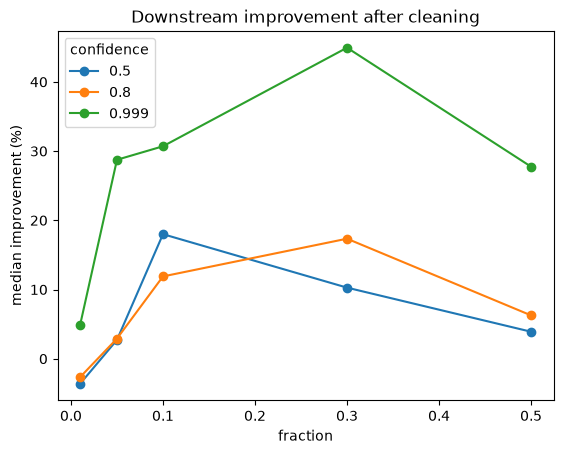

In [16]:
table = results.pivot_table(index="fraction", columns="confidence", values="improvement", aggfunc="median")
table.plot(marker="o", ylabel="median improvement (%)", title="Downstream improvement after cleaning")
table.round(1)

### 7. Comparison with the paper
| | Paper (Fig. 1–2, approx.) | This notebook |
|---|---|---|
| mean TPR at 0.5 / 0.8 / 0.999 | 0.88 / 0.85 / 0.68 | 0.96 / 0.92 / 0.64 |
| mean FPR at 0.5 / 0.8 / 0.999 | 0.47 / 0.32 / 0.13 | 0.63 / 0.36 / 0.02 |
| Higher confidence → better downstream improvement | yes | partly: 0.999 is clearly best (+25.0%); 0.5 (+5.7%) and 0.8 (+4.2%) are similar |
| More errors → bigger improvement | yes | partly: 0.999 rises from +4.9% (1%) to +44.9% (30%), then drops to +27.7% (50%) |
| Low confidence can hurt when there are few errors | yes | yes (0.5: −3.6%, 0.8: −2.6% at 1% errors) |

### 8. Conclusions
- CDC was implemented for numerical columns using conformalized quantile regression, and tested on three OpenML classification datasets.
- The lenient confidence level (0.999) gives the most improvement (median +25.0%), because it only changes values that are clearly outside the believable range (FPR 0.02). The stricter levels (0.5 and 0.8) catch more errors (TPR 0.96 and 0.92), but also wrongly change many good values (FPR 0.63 and 0.36), which leaves only small improvements (+5.7% and +4.2%).
- This matches the paper's main conclusion: a high confidence level is the safest and most effective choice, and low confidence levels can make results worse when there are few errors (−3.6% at 1% errors with confidence 0.5).

### 9. Parameters
| Parameter | Value |
|---|---|
| Datasets | OpenML 823, 30, 40498 (classification, numerical columns, first 5000 rows) |
| Train/test split | 80/20 |
| Confidence levels | 0.5, 0.8, 0.999 |
| Error types | scaling (×10/100/1000/10000), Gaussian noise (std = 3 × column std) |
| Error fractions | 0.01, 0.05, 0.1, 0.3, 0.5 |

### 10. Differences from the paper
- **Models:** AutoGluon is used in the paper; while the simpler and lighter **HistGradientBoostingRegressor** is applied here.
- **Scope:** Numerical columns and classification datasets.
- **Errors:** While the paper uses 4 error types, this implementation uses 2: Scaling and Noise.
- **Scale:** The paper documents 16 datasets and 3 runs, while this implementation uses 3 datasets and 1 run.